# 03 · LightGBM & XGBoost · MLflow Tracking · SHAP · Threshold
**Project 1 — End-to-End ML Pipeline.** Previous: [02 Baselines](02_features_split_baselines.ipynb).

In this notebook we:
1. train **LightGBM** and **XGBoost** (with native categorical support),
2. tune them with cross-validation,
3. **track every experiment with MLflow** (params, metrics, plots, models),
4. pick a decision **threshold** using a cost argument,
5. evaluate on the untouched test set **once**,
6. explain predictions with **SHAP**,
7. export the model for the FastAPI service.

In [1]:
import sys, os, json, time, warnings, joblib; warnings.filterwarnings('ignore'); sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb, xgboost as xgb, mlflow, shap
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve, brier_score_loss)
from src.features import *
sns.set_theme(style='whitegrid'); SEED=42
print('lightgbm', lgb.__version__, '| xgboost', xgb.__version__, '| mlflow', mlflow.__version__)

2026/10/28 05:07:29 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /usr/local/lib/python3.13/dist-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


lightgbm 4.7.0 | xgboost 3.4.1 | mlflow 3.17.2


## 1. Data (same split as notebook 02)

In [2]:
train = pd.read_csv('data/train.csv'); test = pd.read_csv('data/test.csv')
print(train.shape, test.shape)
print('dropout rate: train %.3f | test %.3f' % (train.dropout.mean(), test.dropout.mean()))

(3539, 36) (885, 36)
dropout rate: train 0.321 | test 0.321


In [3]:
def get_xy(frame, stage, levels=None):
    X,y = prepare(frame, stage)
    if levels is not None:
        for c,l in levels.items(): X[c]=pd.Categorical(X[c].astype(int), categories=l)
    return X,y
Xtr1,ytr = get_xy(train,'end_of_sem1')
levels1 = {c: sorted(Xtr1[c].cat.categories.tolist()) for c in CATEGORICAL if c in Xtr1}
Xte1,yte = get_xy(test,'end_of_sem1',levels1)
Xtr1.shape, Xte1.shape

((3539, 31), (885, 31))

In [4]:
Xtr1.dtypes.value_counts()

int64       13
float64      7
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

Category *levels* are fixed from the **training** set and re-applied to the test set (and later, to API requests). Codes unseen in training become missing values — LightGBM and XGBoost both handle that.

## 2. MLflow — set up experiment tracking

MLflow stores every run (parameters, metrics, artifacts) so experiments are **reproducible and comparable**. We use a local SQLite database — no server needed. Later you can run `mlflow ui` and browse everything in a web page.

In [5]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('student-dropout')
print(mlflow.get_tracking_uri()); print(mlflow.get_experiment_by_name('student-dropout').name)

2026/10/28 05:07:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/28 05:07:30 INFO mlflow.store.db.utils: Updating database tables


2026/10/28 05:07:31 INFO mlflow.tracking.fluent: Experiment with name 'student-dropout' does not exist. Creating a new experiment.


sqlite:///mlflow.db
student-dropout


## 3. Helper: cross-validate, then log to MLflow

In [6]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
def metric_dict(y_true, proba, thr=.5):
    pred=(proba>=thr).astype(int)
    return dict(roc_auc=roc_auc_score(y_true,proba), pr_auc=average_precision_score(y_true,proba), f1=f1_score(y_true,pred), recall=recall_score(y_true,pred), precision=precision_score(y_true,pred), accuracy=accuracy_score(y_true,pred), brier=brier_score_loss(y_true,proba))

def cv_and_log(run_name, model, X, y, stage, params=None, tags=None):
    t=time.time(); oof = cross_val_predict(model, X, y, cv=skf, method='predict_proba', n_jobs=1)[:,1]
    m = metric_dict(y, oof)
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({'stage':stage, 'phase':'cv', **(tags or {})})
        mlflow.log_params({**(params or model.get_params()), 'n_features':X.shape[1]})
        mlflow.log_metrics({'cv_'+k:v for k,v in m.items()}); mlflow.log_metric('fit_seconds', time.time()-t)
    return oof, m

## 4. First models with default-ish settings

In [7]:
lgb_base = lgb.LGBMClassifier(n_estimators=300, learning_rate=.05, num_leaves=15, min_child_samples=20, subsample=.8, subsample_freq=1, colsample_bytree=.8, reg_lambda=1.0, random_state=SEED, n_jobs=2, verbose=-1)
oof_lgb0, m = cv_and_log('lgbm-base · sem1', lgb_base, Xtr1, ytr, 'end_of_sem1', tags={'model':'lightgbm'}); pd.Series(m).round(4).to_frame('LightGBM base (CV)')

,LightGBM base (CV)
roc_auc,0.9011
pr_auc,0.8590
f1,0.7584
recall,0.7150
precision,0.8073
accuracy,0.8536
brier,0.1066


In [8]:
xgb_base = xgb.XGBClassifier(n_estimators=300, learning_rate=.05, max_depth=4, subsample=.8, colsample_bytree=.8, reg_lambda=1.0, tree_method='hist', enable_categorical=True, eval_metric='logloss', random_state=SEED, n_jobs=2)
oof_xgb0, m = cv_and_log('xgb-base · sem1', xgb_base, Xtr1, ytr, 'end_of_sem1', tags={'model':'xgboost'}); pd.Series(m).round(4).to_frame('XGBoost base (CV)')

,XGBoost base (CV)
roc_auc,0.8984
pr_auc,0.8549
f1,0.7568
recall,0.7089
precision,0.8117
accuracy,0.8536
brier,0.1077


## 5. Hyper-parameter search (RandomizedSearchCV)

We search 25 random settings per model, scoring by **PR-AUC** (`average_precision`) — the metric suited to a minority positive class. This is fast here (4k rows) but the same code scales.

In [9]:
lgb_space = {'n_estimators':[150,250,400,600],'learning_rate':[.02,.03,.05,.08],'num_leaves':[7,15,31,63],'min_child_samples':[10,20,40,60],'subsample':[.6,.8,1.0],'colsample_bytree':[.5,.7,.9],'reg_lambda':[0,1,5,10],'reg_alpha':[0,.1,1]}
t=time.time()
search_lgb = RandomizedSearchCV(lgb.LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=1, verbose=-1), lgb_space, n_iter=25, scoring='average_precision', cv=skf, random_state=SEED, n_jobs=2, refit=True).fit(Xtr1, ytr)
print(f'{time.time()-t:.0f}s | best CV PR-AUC {search_lgb.best_score_:.4f}'); search_lgb.best_params_

19s | best CV PR-AUC 0.8648


{'subsample': 0.6,
 'reg_lambda': 0,
 'reg_alpha': 0.1,
 'num_leaves': 7,
 'n_estimators': 600,
 'min_child_samples': 10,
 'learning_rate': 0.03,
 'colsample_bytree': 0.7}

In [10]:
res=pd.DataFrame(search_lgb.cv_results_).sort_values('rank_test_score'); res[['rank_test_score','mean_test_score','std_test_score','param_num_leaves','param_learning_rate','param_n_estimators','param_min_child_samples']].head(8).round(4)

,rank_test_score,mean_test_score,std_test_score,param_num_leaves,param_learning_rate,param_n_estimators,param_min_child_samples
5,1,0.8648,0.0118,7,0.03,600,10
6,2,0.8616,0.0100,15,0.02,400,60
1,3,0.8611,0.0108,31,0.05,250,60
3,4,0.8608,0.0091,15,0.05,250,20
18,5,0.8604,0.0103,15,0.02,250,20
10,6,0.8603,0.0106,31,0.03,400,60
24,7,0.8596,0.0118,31,0.05,150,60
0,8,0.8596,0.0104,15,0.05,150,20


In [11]:
xgb_space = {'n_estimators':[150,250,400,600],'learning_rate':[.02,.03,.05,.08],'max_depth':[2,3,4,5,6],'min_child_weight':[1,3,5,10],'subsample':[.6,.8,1.0],'colsample_bytree':[.5,.7,.9],'reg_lambda':[0,1,5,10],'gamma':[0,.5,1]}
t=time.time()
search_xgb = RandomizedSearchCV(xgb.XGBClassifier(tree_method='hist', enable_categorical=True, eval_metric='logloss', random_state=SEED, n_jobs=1), xgb_space, n_iter=25, scoring='average_precision', cv=skf, random_state=SEED, n_jobs=2, refit=True).fit(Xtr1, ytr)
print(f'{time.time()-t:.0f}s | best CV PR-AUC {search_xgb.best_score_:.4f}'); search_xgb.best_params_

22s | best CV PR-AUC 0.8604


{'subsample': 1.0,
 'reg_lambda': 1,
 'n_estimators': 600,
 'min_child_weight': 10,
 'max_depth': 4,
 'learning_rate': 0.02,
 'gamma': 1,
 'colsample_bytree': 0.7}

In [12]:
res=pd.DataFrame(search_xgb.cv_results_).sort_values('rank_test_score'); res[['rank_test_score','mean_test_score','std_test_score','param_max_depth','param_learning_rate','param_n_estimators']].head(8).round(4)

,rank_test_score,mean_test_score,std_test_score,param_max_depth,param_learning_rate,param_n_estimators
12,1,0.8604,0.0093,4,0.02,600
10,2,0.8598,0.0097,4,0.03,400
23,3,0.8594,0.0107,3,0.03,250
19,4,0.8591,0.0094,6,0.05,150
18,5,0.8588,0.0114,2,0.08,600
4,6,0.8584,0.0109,4,0.03,150
2,7,0.8581,0.0092,5,0.08,150
11,8,0.8578,0.0112,3,0.05,150


## 6. Log the tuned candidates and compare

In [13]:
oof_lgb, m_lgb = cv_and_log('lgbm-tuned · sem1', search_lgb.best_estimator_, Xtr1, ytr, 'end_of_sem1', tags={'model':'lightgbm','tuned':'yes'})
oof_xgb, m_xgb = cv_and_log('xgb-tuned · sem1', search_xgb.best_estimator_, Xtr1, ytr, 'end_of_sem1', tags={'model':'xgboost','tuned':'yes'})
pd.DataFrame({'LightGBM tuned':m_lgb,'XGBoost tuned':m_xgb}).round(4)

,LightGBM tuned,XGBoost tuned
roc_auc,0.9070,0.9021
pr_auc,0.8634,0.8591
f1,0.7682,0.7583
recall,0.7186,0.7036
precision,0.8253,0.8222
accuracy,0.8607,0.8559
brier,0.1036,0.1056


In [14]:
runs = mlflow.search_runs(experiment_names=['student-dropout'], order_by=['metrics.cv_pr_auc DESC'])
runs[['tags.mlflow.runName','metrics.cv_roc_auc','metrics.cv_pr_auc','metrics.cv_f1','metrics.cv_recall','metrics.cv_precision','metrics.fit_seconds']].round(4)

,tags.mlflow.runName,metrics.cv_roc_auc,metrics.cv_pr_auc,metrics.cv_f1,metrics.cv_recall,metrics.cv_precision,metrics.fit_seconds
0,lgbm-tuned · sem1,0.9070,0.8634,0.7682,0.7186,0.8253,1.4655
1,xgb-tuned · sem1,0.9021,0.8591,0.7583,0.7036,0.8222,1.8833
2,lgbm-base · sem1,0.9011,0.8590,0.7584,0.7150,0.8073,1.1161
3,xgb-base · sem1,0.8984,0.8549,0.7568,0.7089,0.8117,1.3141


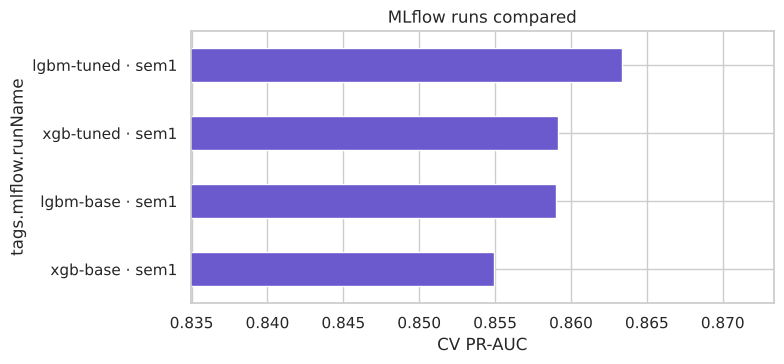

In [15]:
fig,ax=plt.subplots(figsize=(8,3.8)); r=runs.set_index('tags.mlflow.runName')['metrics.cv_pr_auc'].sort_values(); r.plot(kind='barh',color='slateblue'); plt.xlim(r.min()-.02,r.max()+.01); plt.xlabel('CV PR-AUC'); plt.title('MLflow runs compared'); plt.tight_layout(); plt.show()

Compare with the logistic-regression baseline from notebook 02 (sem-1 CV ROC-AUC ≈ 0.90). Gradient boosting usually adds a small, not dramatic, improvement on a dataset this size — the honest result matters more than a flashy one.

## 7. Choose the champion

In [16]:
champ_name = 'LightGBM' if m_lgb['pr_auc']>=m_xgb['pr_auc'] else 'XGBoost'
champ = search_lgb.best_estimator_ if champ_name=='LightGBM' else search_xgb.best_estimator_
oof = oof_lgb if champ_name=='LightGBM' else oof_xgb
print('Champion for the early-warning model:', champ_name)

Champion for the early-warning model: LightGBM


## 8. Choose the decision threshold with a cost argument

The default threshold 0.5 is arbitrary. In reality:

| Error | Cost |
|---|---|
| Miss a student who drops out (false negative) | high — a lost student, lost fees |
| Flag a student who would have stayed (false positive) | low — one extra counselling chat |

So we favour **recall**. We use the **F2 score** (recall counts 2× more than precision) and choose the threshold on the *out-of-fold* predictions from the training set — never on the test set.

In [17]:
ths=np.linspace(.05,.95,91); tab=pd.DataFrame({'thr':ths,'precision':[precision_score(ytr,oof>=t) for t in ths],'recall':[recall_score(ytr,oof>=t) for t in ths],'f1':[f1_score(ytr,oof>=t) for t in ths],'f2':[fbeta_score(ytr,oof>=t,beta=2) for t in ths]})
best_thr=float(tab.loc[tab.f2.idxmax(),'thr']); print('chosen threshold (max F2 on OOF):', round(best_thr,2)); tab.loc[tab.f2.idxmax()].round(3)

chosen threshold (max F2 on OOF): 0.17


thr          0.170
precision    0.621
recall       0.882
f1           0.729
f2           0.814
Name: 12, dtype: float64

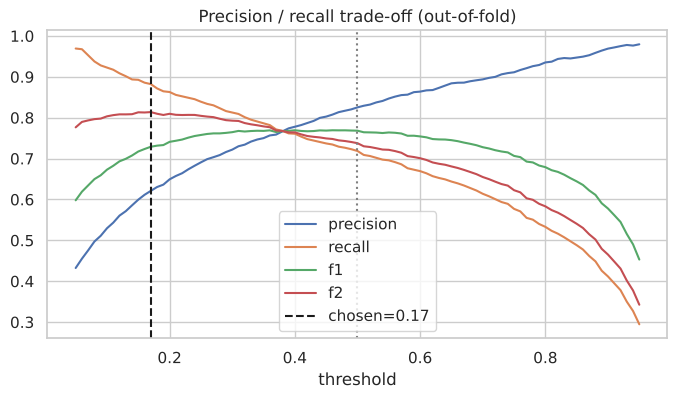

In [18]:
plt.figure(figsize=(8,4)); [plt.plot(tab.thr,tab[c],label=c) for c in ['precision','recall','f1','f2']]; plt.axvline(best_thr,color='k',ls='--',label=f'chosen={best_thr:.2f}'); plt.axvline(.5,color='gray',ls=':'); plt.legend(); plt.xlabel('threshold'); plt.title('Precision / recall trade-off (out-of-fold)'); plt.show()

## 9. Final fit on the full training set → evaluate on the test set ONCE

In [19]:
final = champ.__class__(**champ.get_params()).fit(Xtr1, ytr)
proba_te = final.predict_proba(Xte1)[:,1]
test_m = metric_dict(yte, proba_te, best_thr); pd.Series(test_m).round(4).to_frame('TEST (threshold=%.2f)'%best_thr)

,TEST (threshold=0.17)
roc_auc,0.9122
pr_auc,0.8816
f1,0.7388
recall,0.9014
precision,0.6259
accuracy,0.7955
brier,0.0959


In [20]:
test_m_05 = metric_dict(yte, proba_te, .5); pd.DataFrame({'thr=0.5':test_m_05,f'thr={best_thr:.2f}':test_m}).round(4)

,thr=0.5,thr=0.17
roc_auc,0.9122,0.9122
pr_auc,0.8816,0.8816
f1,0.7805,0.7388
recall,0.7324,0.9014
precision,0.8353,0.6259
accuracy,0.8678,0.7955
brier,0.0959,0.0959


Of 284 students who dropped out we caught 256 (90%). We also flagged 153 students who stayed (25% of stayers).


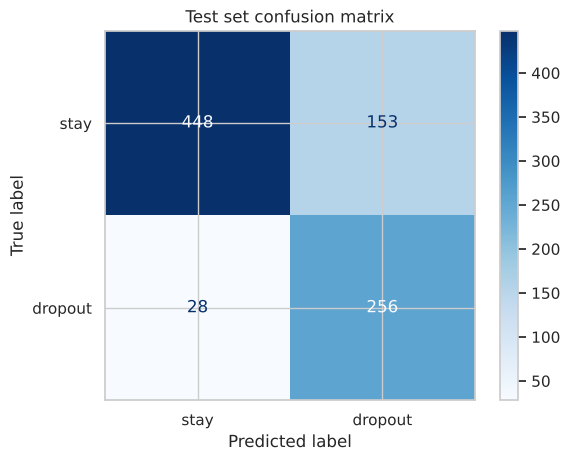

In [21]:
cm=confusion_matrix(yte,(proba_te>=best_thr).astype(int)); tn,fp,fn,tp=cm.ravel(); print(f'Of {tp+fn} students who dropped out we caught {tp} ({tp/(tp+fn):.0%}). We also flagged {fp} students who stayed ({fp/(tn+fp):.0%} of stayers).')
ConfusionMatrixDisplay(cm,display_labels=['stay','dropout']).plot(cmap='Blues'); plt.title('Test set confusion matrix'); plt.show()

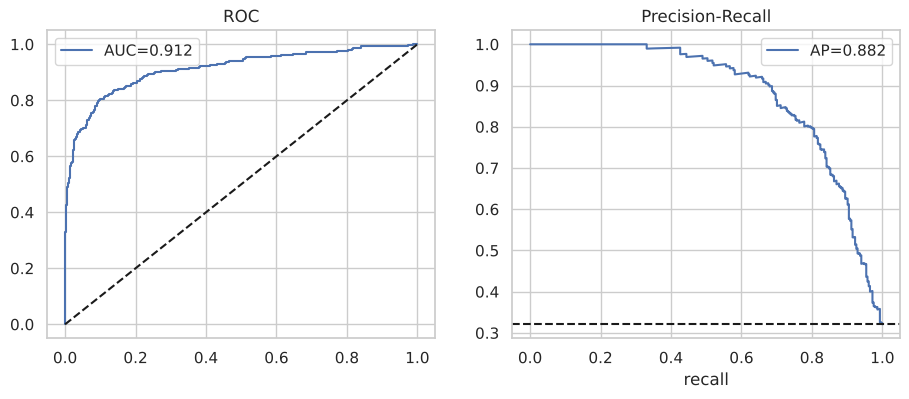

In [22]:
fpr,tpr,_=roc_curve(yte,proba_te); p,r,_=precision_recall_curve(yte,proba_te)
fig,ax=plt.subplots(1,2,figsize=(11,4)); ax[0].plot(fpr,tpr,label=f"AUC={test_m['roc_auc']:.3f}"); ax[0].plot([0,1],[0,1],'k--'); ax[0].legend(); ax[0].set_title('ROC'); ax[1].plot(r,p,label=f"AP={test_m['pr_auc']:.3f}"); ax[1].axhline(yte.mean(),color='k',ls='--'); ax[1].legend(); ax[1].set_title('Precision-Recall'); ax[1].set_xlabel('recall'); plt.show()

### Calibration — can we trust the probabilities?

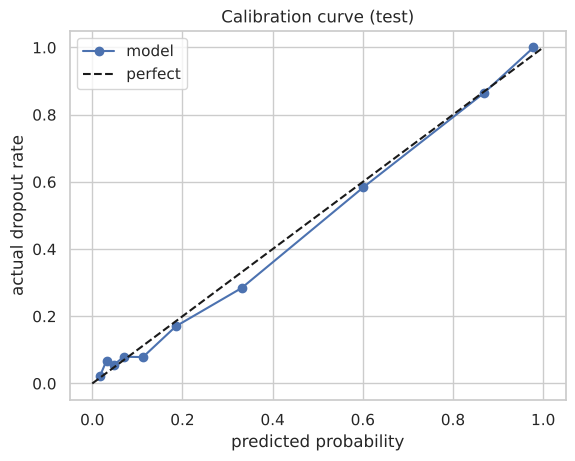

Brier score: 0.0959


In [23]:
frac,mean=calibration_curve(yte,proba_te,n_bins=10,strategy='quantile'); plt.plot(mean,frac,'o-',label='model'); plt.plot([0,1],[0,1],'k--',label='perfect'); plt.xlabel('predicted probability'); plt.ylabel('actual dropout rate'); plt.legend(); plt.title('Calibration curve (test)'); plt.show(); print('Brier score:', round(test_m['brier'],4))

In [24]:
te=test.copy(); te['proba']=proba_te; b2=max(.5,best_thr+.05); b3=max(.8,b2+.05); print('risk bands: low <',round(best_thr,2),'| medium <',round(b2,2),'| high <',round(b3,2),'| very high above'); te['risk']=pd.cut(te.proba,[0,best_thr,b2,b3,1.0],labels=['low','medium','high','very high'],include_lowest=True)
te.groupby('risk').dropout.agg(['mean','count']).round(3)

risk bands: low < 0.17 | medium < 0.5 | high < 0.8 | very high above


,mean,count
risk,,
low,0.059,476
medium,0.300,160
high,0.633,90
very high,0.950,159


Students in the higher-risk bands drop out much more often (see the table) — the model gives useful *risk levels*, not just yes/no.

## 10. Log the final model to MLflow

In [25]:
with mlflow.start_run(run_name=f'FINAL {champ_name} · sem1') as run:
    mlflow.set_tags({'stage':'end_of_sem1','phase':'final','model':champ_name.lower()})
    mlflow.log_params({**final.get_params(),'threshold':round(best_thr,2)})
    mlflow.log_metrics({'test_'+k:v for k,v in test_m.items()}); mlflow.log_metrics({'cv_'+k:v for k,v in metric_dict(ytr,oof,best_thr).items()})
    fig_path='models/test_confusion.png'; os.makedirs('models',exist_ok=True)
    ConfusionMatrixDisplay(cm,display_labels=['stay','dropout']).plot(cmap='Blues'); plt.savefig(fig_path,dpi=110); plt.close(); mlflow.log_artifact(fig_path)
    final_run_id=run.info.run_id
print('logged run', final_run_id)

logged run 3ce4deb0909044048eea66663fdb7f27


## 11. SHAP — why does the model flag a student?

In [26]:
expl = shap.TreeExplainer(final); sv = expl.shap_values(Xte1)
sv = sv[1] if isinstance(sv,list) else (sv[:,:,1] if getattr(sv,'ndim',2)==3 else sv); print(sv.shape)

(885, 31)


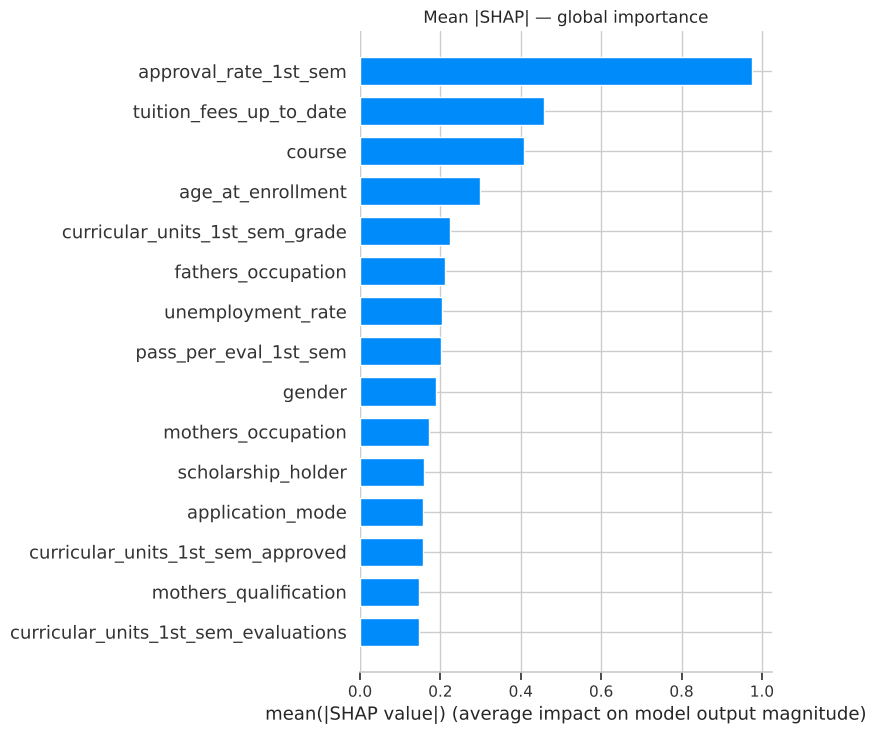

In [27]:
shap.summary_plot(sv, Xte1, plot_type='bar', max_display=15, show=False); plt.title('Mean |SHAP| — global importance'); plt.tight_layout(); plt.show()

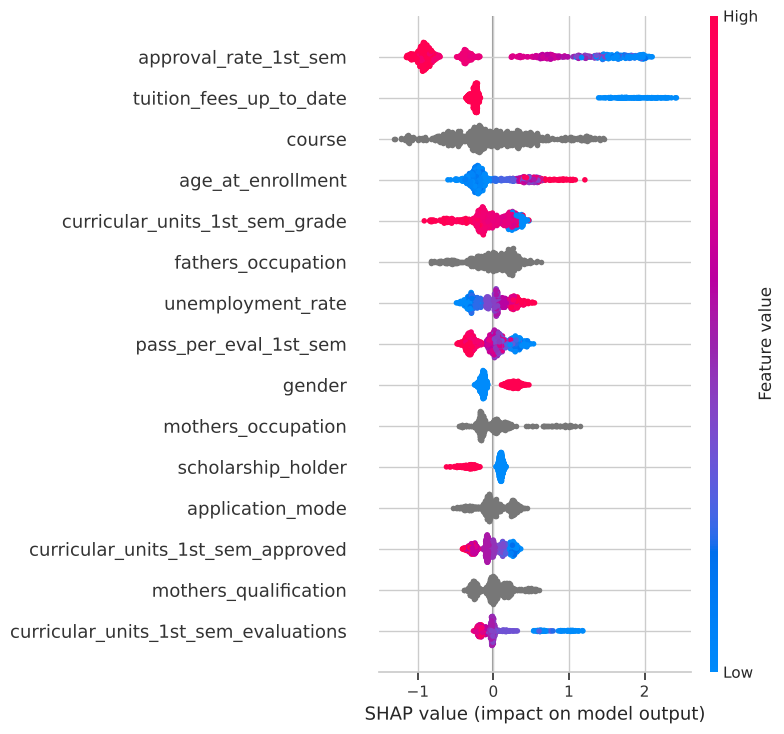

In [28]:
shap.summary_plot(sv, Xte1, max_display=15, show=False); plt.tight_layout(); plt.show()

In [29]:
imp=pd.Series(np.abs(sv).mean(0),index=Xte1.columns).sort_values(ascending=False); imp.head(10).round(4).to_frame('mean |SHAP|')

,mean |SHAP|
approval_rate_1st_sem,0.9754
tuition_fees_up_to_date,0.4585
course,0.4089
age_at_enrollment,0.2991
curricular_units_1st_sem_grade,0.2251
fathers_occupation,0.2105
unemployment_rate,0.2031
pass_per_eval_1st_sem,0.2007
gender,0.1880
mothers_occupation,0.1718


The top drivers are the semester-1 **approval rate**, **tuition fees up to date**, **course**, **age at enrollment** and semester-1 **grade**. The first, second, fourth and fifth agree with the EDA in notebook 01 (the course effect is also visible in the dropout-rate-by-course chart) — a sanity check that the model learned real patterns, not noise. Note that economic context (`unemployment_rate`) appears in the top 10 even though EDA showed little difference between groups; this is a reminder that SHAP importance does not mean a causal effect.

### Explain individual students

In [30]:
def explain_row(i, k=6):
    row=Xte1.iloc[i]; contrib=pd.Series(sv[i],index=Xte1.columns).sort_values(key=abs,ascending=False).head(k)
    print(f'Student #{i}: predicted dropout probability = {proba_te[i]:.2f} | actual = {"dropout" if yte.iloc[i] else "no dropout"}')
    for f,v in contrib.items(): print(f'   {"↑ risk" if v>0 else "↓ risk"}  {f:42s} value={row[f]!s:8s} impact={v:+.2f}')
hi=int(np.argmax(proba_te)); lo=int(np.argmin(proba_te)); explain_row(hi); print(); explain_row(lo)

Student #90: predicted dropout probability = 1.00 | actual = dropout
   ↑ risk  tuition_fees_up_to_date                    value=0.0      impact=+1.54
   ↑ risk  approval_rate_1st_sem                      value=0.0      impact=+1.49
   ↑ risk  age_at_enrollment                          value=45.0     impact=+1.05
   ↑ risk  mothers_occupation                         value=1.0      impact=+0.86
   ↑ risk  course                                     value=11.0     impact=+0.64
   ↑ risk  mothers_qualification                      value=19.0     impact=+0.47

Student #450: predicted dropout probability = 0.01 | actual = no dropout
   ↓ risk  course                                     value=2.0      impact=-0.94
   ↓ risk  approval_rate_1st_sem                      value=1.0      impact=-0.88
   ↑ risk  curricular_units_1st_sem_credited          value=15.0     impact=+0.48
   ↓ risk  curricular_units_1st_sem_approved          value=17.0     impact=-0.36
   ↓ risk  scholarship_holder        

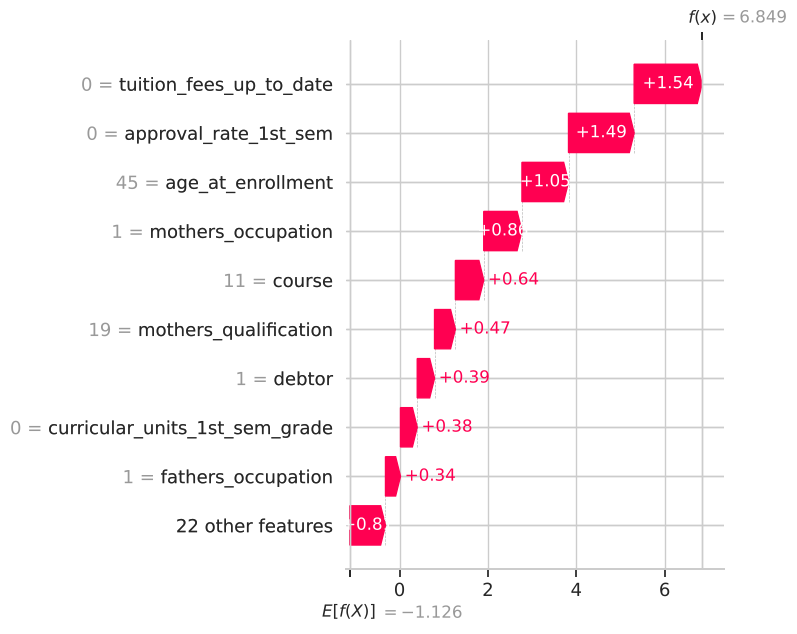

In [31]:
shap.plots.waterfall(shap.Explanation(values=sv[hi], base_values=expl.expected_value if np.isscalar(expl.expected_value) else expl.expected_value[1], data=Xte1.iloc[hi].values, feature_names=list(Xte1.columns)), max_display=10, show=False); plt.tight_layout(); plt.show()

## 12. Early warning (sem 1) vs full model (sem 2)

In [32]:
Xtr2,_=get_xy(train,'end_of_sem2'); levels2={c: sorted(Xtr2[c].cat.categories.tolist()) for c in CATEGORICAL if c in Xtr2}; Xte2,_=get_xy(test,'end_of_sem2',levels2)
m2=champ.__class__(**champ.get_params())
oof2,mcv2=cv_and_log(f'{champ_name}-tuned-params · sem2', m2, Xtr2, ytr, 'end_of_sem2', tags={'model':champ_name.lower()})
thr2=float(pd.Series({t:fbeta_score(ytr,oof2>=t,beta=2) for t in ths}).idxmax())
final2=champ.__class__(**champ.get_params()).fit(Xtr2,ytr); p2=final2.predict_proba(Xte2)[:,1]; test_m2=metric_dict(yte,p2,thr2)
pd.DataFrame({'sem1 (early)':test_m,'sem2 (full)':test_m2}).round(4)

,sem1 (early),sem2 (full)
roc_auc,0.9122,0.9342
pr_auc,0.8816,0.9092
f1,0.7388,0.7418
recall,0.9014,0.9155
precision,0.6259,0.6235
accuracy,0.7955,0.7955
brier,0.0959,0.0813


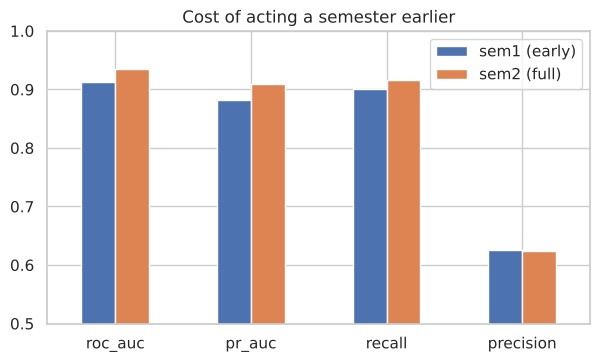

In [33]:
cmp=pd.DataFrame({'sem1 (early)':test_m,'sem2 (full)':test_m2}).loc[['roc_auc','pr_auc','recall','precision']]; cmp.plot(kind='bar',figsize=(7,3.8)); plt.ylim(.5,1); plt.xticks(rotation=0); plt.title('Cost of acting a semester earlier'); plt.show()

The early model gives up some accuracy to be available **a whole semester sooner**. For a retention programme, early and slightly less certain usually beats late and more certain.

## 13. Export artefacts for the API

In [34]:
os.makedirs('models',exist_ok=True)
meta={'stage':'end_of_sem1','model':champ_name,'threshold':round(best_thr,3),'features':list(Xtr1.columns),'categorical':[c for c in CATEGORICAL if c in Xtr1],'levels':{c:[int(v) for v in l] for c,l in levels1.items()},'test_metrics':{k:round(float(v),4) for k,v in test_m.items()},'mlflow_run_id':final_run_id,'train_rows':int(len(Xtr1))}
joblib.dump(final,'models/model_sem1.joblib'); json.dump(meta,open('models/model_meta.json','w'),indent=2)
print(os.path.getsize('models/model_sem1.joblib')//1024,'KB'); print(json.dumps({k:meta[k] for k in ['stage','model','threshold','test_metrics']},indent=1))

537 KB
{
 "stage": "end_of_sem1",
 "model": "LightGBM",
 "threshold": 0.17,
 "test_metrics": {
  "roc_auc": 0.9122,
  "pr_auc": 0.8816,
  "f1": 0.7388,
  "recall": 0.9014,
  "precision": 0.6259,
  "accuracy": 0.7955,
  "brier": 0.0959
 }
}


In [35]:
loaded=joblib.load('models/model_sem1.joblib'); print('reload check, max abs diff:', float(np.abs(loaded.predict_proba(Xte1)[:,1]-proba_te).max()))

reload check, max abs diff: 0.0


In [36]:
pd.DataFrame(search_lgb.cv_results_).to_csv('models/lgbm_search.csv',index=False); pd.DataFrame(search_xgb.cv_results_).to_csv('models/xgb_search.csv',index=False); runs.to_csv('models/mlflow_runs_summary.csv',index=False); print('saved')

saved


## 14. Summary
| Item | Result |
|---|---|
| Problem | flag students likely to drop out, as early as possible |
| Champion (sem 1) | see §7 / §9 (tuned gradient-boosted trees) |
| Tracking | every run logged to MLflow (`mlflow ui`) |
| Threshold | chosen on out-of-fold data with an F2 (recall-weighted) argument |
| Test evaluation | done once, at the end |
| Explanations | SHAP, consistent with the EDA |

**Next:** serve the model with **FastAPI + Docker** (see `api/` and the README).